# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary. 

**Business problem.** A used car dealership wants to know which characteristics of a vehicle make it more or less expensive, so it can buy and price inventory that consumers value.

**Data problem definition.** This is a *supervised regression* problem. The target variable is the listing `price` (continuous, in USD). The predictors are vehicle attributes: manufacturer, model year / age, odometer reading, condition, cylinders, fuel type, transmission, drive train, body type, title status, paint colour and state. The goal is twofold:

1. **Predict** price accurately, so that we know the attributes carry real signal.
2. **Explain** price, by quantifying how much each attribute is associated with price once the others are held constant (regression coefficients and permutation feature importance).

**Success criteria.** We use *RMSE on log(price)* as the main evaluation metric because prices are highly right-skewed and dealers think in percentage differences, not absolute dollars (a $2,000 error is huge on a $5,000 car and trivial on a $60,000 car). We also report MAE in dollars and R² for a plain-language error figure. Models are compared with 5-fold cross-validation and then confirmed on a held-out test set.

In [1]:
# Libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
RANDOM_STATE = 42

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

**Plan for getting to know the data:** (1) load it and check size, column types and a few rows; (2) measure missing values per column; (3) look at the distribution of the target (`price`) and the main numeric predictors; (4) check categorical columns for odd or rare values; (5) look for integrity problems such as impossible values and duplicate listings.

In [2]:
# 1. Load the data and take a first look
df_raw = pd.read_csv('data/vehicles.csv')
print(f'Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}')
df_raw.head()

Rows: 426,880   Columns: 18


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


In [3]:
# 2. Column types, number of distinct values and % missing in one compact table
overview = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'n_unique': df_raw.nunique(),
    'pct_missing': (df_raw.isna().mean() * 100).round(1),
}).sort_values('pct_missing', ascending=False)
overview

,dtype,n_unique,pct_missing
size,object,4,71.8
cylinders,object,8,41.6
condition,object,6,40.8
VIN,object,118246,37.7
drive,object,3,30.6
paint_color,object,12,30.5
type,object,13,21.8
manufacturer,object,42,4.1
title_status,object,6,1.9
model,object,29649,1.2


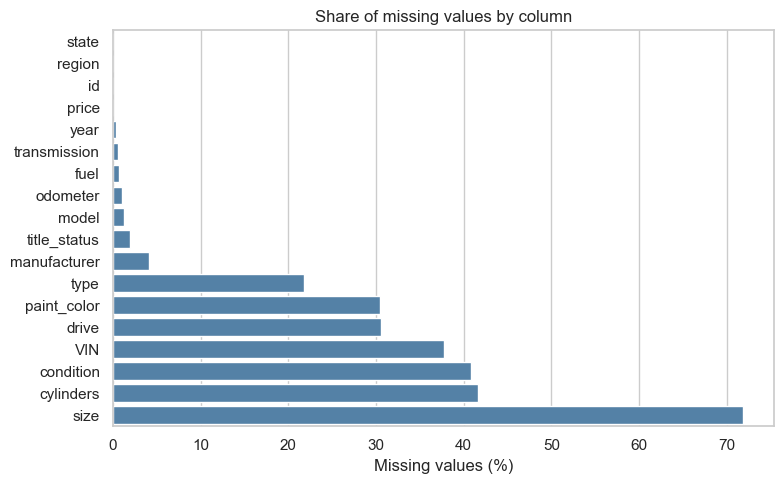

In [4]:
# Missing values by column
fig, ax = plt.subplots(figsize=(8, 5))
miss = overview['pct_missing'].sort_values()
sns.barplot(x=miss.values, y=miss.index, color='steelblue', ax=ax)
ax.set_title('Share of missing values by column')
ax.set_xlabel('Missing values (%)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

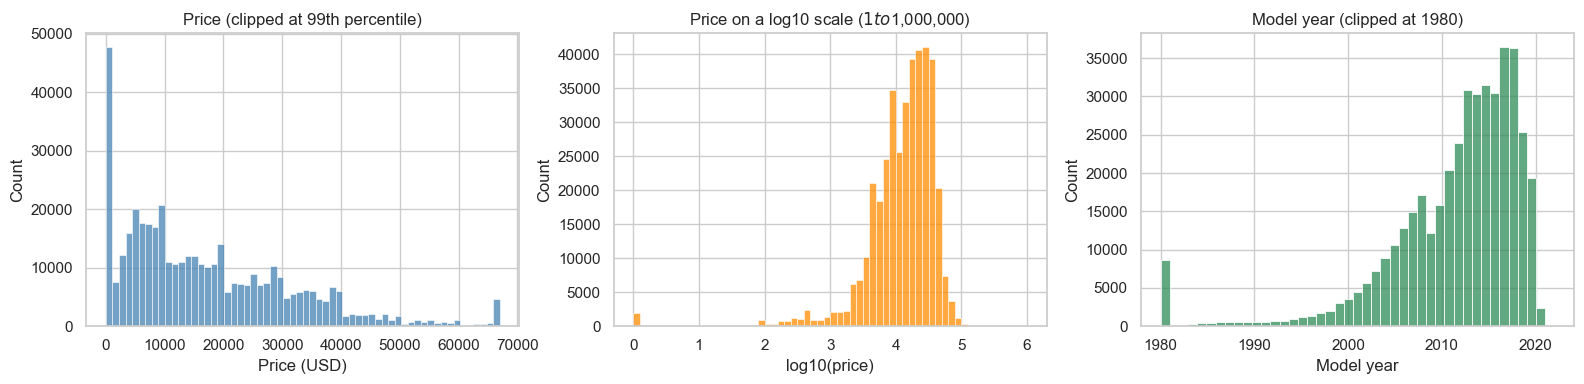

count          426,880
mean            75,199
std         12,182,282
min                  0
25%              5,900
50%             13,950
75%             26,486
max      3,736,928,711


In [5]:
# 3. Distribution of the target and key numeric variables (raw data)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_raw['price'].clip(upper=df_raw['price'].quantile(0.99)), bins=60, ax=axes[0], color='steelblue')
axes[0].set_title('Price (clipped at 99th percentile)')
axes[0].set_xlabel('Price (USD)')

sns.histplot(np.log10(df_raw.loc[df_raw['price'].between(1, 1_000_000), 'price']), bins=60, ax=axes[1], color='darkorange')
axes[1].set_title('Price on a log10 scale ($1 to $1,000,000)')
axes[1].set_xlabel('log10(price)')

sns.histplot(df_raw['year'].dropna().clip(lower=1980), bins=43, ax=axes[2], color='seagreen')
axes[2].set_title('Model year (clipped at 1980)')
axes[2].set_xlabel('Model year')

plt.tight_layout()
plt.show()

print(df_raw['price'].describe().apply('{:,.0f}'.format).to_string())

In [6]:
# 4. Data-quality checks: impossible / suspicious values and duplicates
quality = pd.Series({
    'Listings with price = 0': (df_raw['price'] == 0).sum(),
    'Listings with price < $1,000': (df_raw['price'] < 1000).sum(),
    'Listings with price > $100,000': (df_raw['price'] > 100_000).sum(),
    'Listings with price > $1,000,000': (df_raw['price'] > 1_000_000).sum(),
    'Odometer > 400,000 miles': (df_raw['odometer'] > 400_000).sum(),
    'Odometer < 100 miles': (df_raw['odometer'] < 100).sum(),
    'Model year before 1995': (df_raw['year'] < 1995).sum(),
    'Duplicate rows (ignoring id, VIN, region)': df_raw.drop(columns=['id', 'VIN', 'region']).duplicated().sum(),
})
quality.to_frame('count').assign(pct=lambda t: (t['count'] / len(df_raw) * 100).round(2))

,count,pct
Listings with price = 0,32895,7.71
"Listings with price < $1,000",46315,10.85
"Listings with price > $100,000",655,0.15
"Listings with price > $1,000,000",53,0.01
"Odometer > 400,000 miles",1702,0.40
Odometer < 100 miles,6640,1.56
Model year before 1995,15896,3.72
"Duplicate rows (ignoring id, VIN, region)",127690,29.91


In [7]:
# 5. Categorical columns: levels and counts (high-cardinality columns shown as counts only)
for col in ['condition', 'fuel', 'title_status', 'transmission', 'drive', 'type']:
    print(col, '->', df_raw[col].value_counts(dropna=False).to_dict())
print()
print('Distinct values -> manufacturer:', df_raw['manufacturer'].nunique(),
      '| model:', df_raw['model'].nunique(),
      '| region:', df_raw['region'].nunique(),
      '| state:', df_raw['state'].nunique())

condition -> {nan: 174104, 'good': 121456, 'excellent': 101467, 'like new': 21178, 'fair': 6769, 'new': 1305, 'salvage': 601}
fuel -> {'gas': 356209, 'other': 30728, 'diesel': 30062, 'hybrid': 5170, nan: 3013, 'electric': 1698}
title_status -> {'clean': 405117, nan: 8242, 'rebuilt': 7219, 'salvage': 3868, 'lien': 1422, 'missing': 814, 'parts only': 198}
transmission -> {'automatic': 336524, 'other': 62682, 'manual': 25118, nan: 2556}
drive -> {'4wd': 131904, nan: 130567, 'fwd': 105517, 'rwd': 58892}
type -> {nan: 92858, 'sedan': 87056, 'SUV': 77284, 'pickup': 43510, 'truck': 35279, 'other': 22110, 'coupe': 19204, 'hatchback': 16598, 'wagon': 10751, 'van': 8548, 'convertible': 7731, 'mini-van': 4825, 'offroad': 609, 'bus': 517}

Distinct values -> manufacturer: 42 | model: 29649 | region: 404 | state: 51


**What we learn from the first look**

* **The target is extremely skewed and contains junk.** About 7.7% of listings have a price of $0 and a handful are in the billions (placeholder prices). On a log scale the distribution of real prices is close to bell-shaped, so modelling `log(price)` is appropriate.
* **Numeric predictors contain impossible values** (odometer readings in the millions, cars from 1900), which would badly distort a linear model.
* **Missingness is large in several useful columns:** `condition` (41%), `cylinders` (42%), `drive` (31%), `paint_color` (31%), `type` (22%) and especially `size` (72%). Dropping every incomplete row would throw away most of the data, so missing categories will be kept as their own level (`unknown`).
* **Identifier-like columns carry no pricing information:** `id`, `VIN` (38% missing and not comparable across cars), `region` (404 levels, overlaps with `state`) and `model` (about 30,000 free-text levels). These are removed rather than one-hot encoded.
* **Many duplicate listings exist** (the same car posted in several regions), which would leak between training and test data if kept.

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

**Data-preparation decisions**

| Step | Decision | Reason |
|---|---|---|
| Drop columns | `id`, `VIN`, `region`, `model`, `size` | identifiers, redundant with `state`, ~30,000 free-text levels, 72% missing |
| Price filter | keep $1,000 – $100,000 | removes $0 / placeholder prices and extreme outliers; this is the range a dealership actually stocks |
| Odometer filter | keep 100 – 400,000 miles | removes data-entry errors (e.g. 1,111,111) and "0 mile" placeholders |
| Year filter | keep model years 1995 and newer | older cars are collectibles priced by different rules than everyday used cars |
| Required fields | drop rows missing `year`, `odometer` or `manufacturer` | tiny share of rows, core drivers of price |
| Duplicates | drop identical listings | same car posted multiple times |
| New features | `age` = 2022 − year; `cyl` = number of cylinders as a number | age is easier to interpret than year; cylinders become numeric |
| Missing categories | filled with `unknown` | keeps rows and lets the model learn whether *missing* is informative |
| Target | `log(price)` | removes right-skew, errors become percentages |

In [8]:
# Build the modelling dataset step by step and record how many rows survive each step
steps = []
df = df_raw.copy()
steps.append(('Original data', len(df)))

df = df.drop(columns=['id', 'VIN', 'region', 'model', 'size'])

df = df[df['price'].between(1_000, 100_000)]
steps.append(('Price between $1,000 and $100,000', len(df)))

df = df[df['odometer'].between(100, 400_000)]
steps.append(('Odometer between 100 and 400,000 miles', len(df)))

df = df[df['year'] >= 1995]
steps.append(('Model year 1995 or newer', len(df)))

df = df.dropna(subset=['year', 'odometer', 'manufacturer'])
steps.append(('Year, odometer and manufacturer present', len(df)))

df = df.drop_duplicates()
steps.append(('Duplicate listings removed', len(df)))

# Feature engineering
df['age'] = (2022 - df['year']).astype(int)                    # dataset's newest model year is 2022
df['cyl'] = df['cylinders'].str.extract(r'(\d+)').astype(float)  # '6 cylinders' -> 6.0 ('other' stays NaN)
df = df.drop(columns=['year', 'cylinders'])

# Missing categories become their own level
cat_cols = ['manufacturer', 'condition', 'fuel', 'title_status', 'transmission',
            'drive', 'type', 'paint_color', 'state']
df[cat_cols] = df[cat_cols].fillna('unknown')
df['log_price'] = np.log1p(df['price'])

funnel = pd.DataFrame(steps, columns=['Step', 'Rows remaining'])
funnel['% of original'] = (funnel['Rows remaining'] / len(df_raw) * 100).round(1)
funnel

,Step,Rows remaining,% of original
0,Original data,426880,100.0
1,"Price between $1,000 and $100,000",379910,89.0
2,"Odometer between 100 and 400,000 miles",372155,87.2
3,Model year 1995 or newer,357339,83.7
4,"Year, odometer and manufacturer present",346758,81.2
5,Duplicate listings removed,241193,56.5


In [9]:
# Final check of the cleaned data
print(f'Cleaned data: {df.shape[0]:,} rows x {df.shape[1]} columns')
print('Remaining missing values (only cylinders, which the model imputes with the median):')
print(df.isna().sum()[lambda s: s > 0].to_string())
df[['price', 'age', 'odometer', 'cyl']].describe().round(1)

Cleaned data: 241,193 rows x 14 columns
Remaining missing values (only cylinders, which the model imputes with the median):
cyl    92114


,price,age,odometer,cyl
count,241193.0,241193.0,241193.0,149079.0
mean,18059.0,10.0,98366.7,5.9
std,13808.5,5.7,63382.2,1.6
min,1000.0,0.0,100.0,3.0
25%,7000.0,5.0,44000.0,4.0
50%,14590.0,9.0,94321.0,6.0
75%,25990.0,14.0,141000.0,8.0
max,100000.0,27.0,400000.0,12.0


### Exploring the cleaned data

Before modelling we look at how price relates to the main attributes. This gives us expectations to compare the models against.

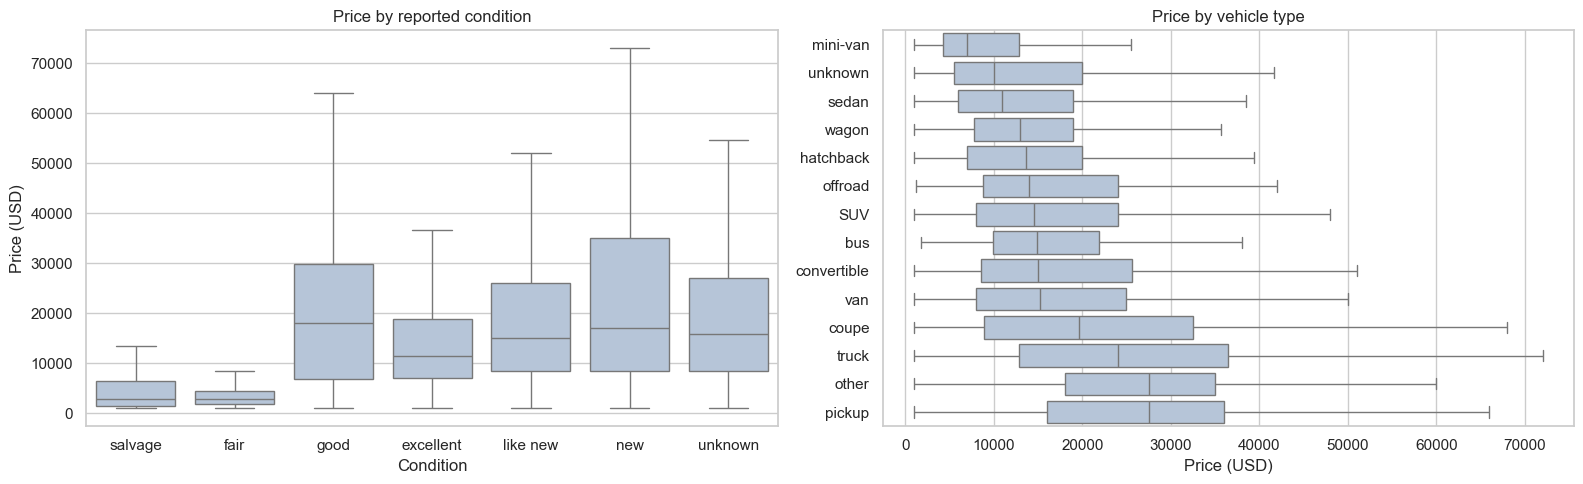

In [10]:
# Price vs. condition and vehicle type (categorical variables -> box plots)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

cond_order = ['salvage', 'fair', 'good', 'excellent', 'like new', 'new', 'unknown']
sns.boxplot(data=df, x='condition', y='price', order=cond_order, ax=axes[0], color='lightsteelblue', showfliers=False)
axes[0].set_title('Price by reported condition')
axes[0].set_xlabel('Condition')
axes[0].set_ylabel('Price (USD)')

type_order = df.groupby('type')['price'].median().sort_values().index
sns.boxplot(data=df, x='price', y='type', order=type_order, ax=axes[1], color='lightsteelblue', showfliers=False)
axes[1].set_title('Price by vehicle type')
axes[1].set_xlabel('Price (USD)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

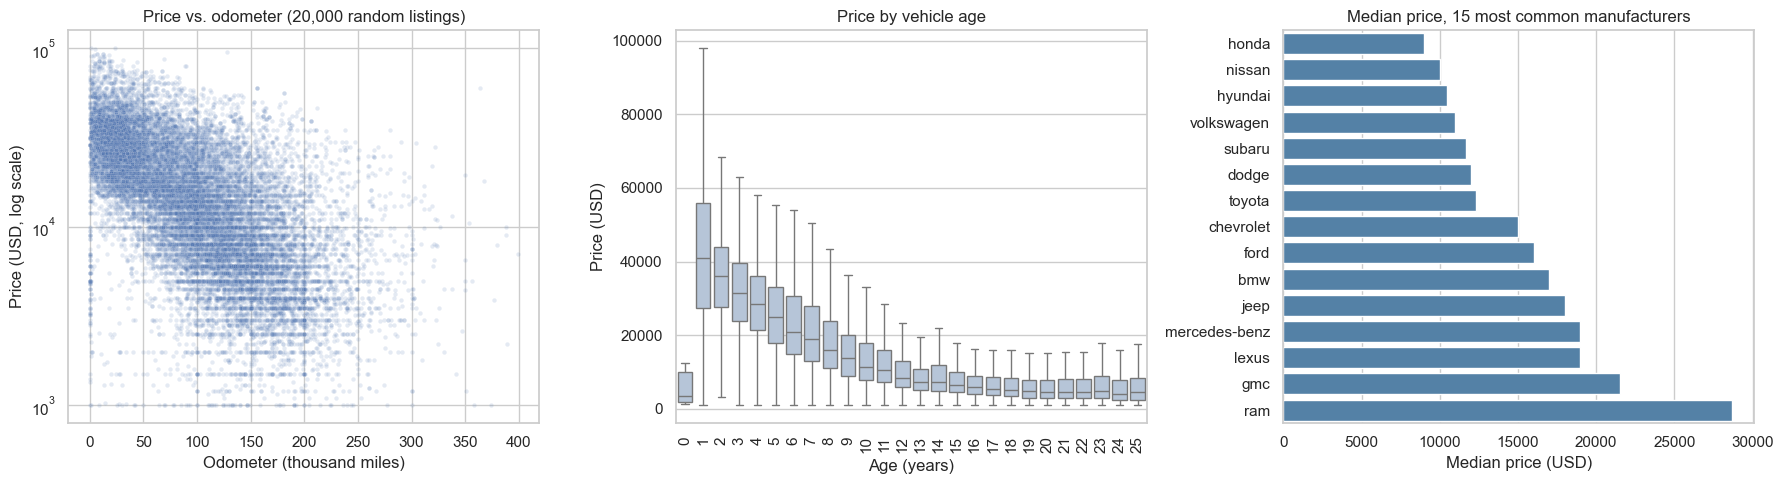

In [11]:
# Price vs. age and odometer (continuous variables)
sample = df.sample(20_000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=sample['odometer'] / 1000, y=sample['price'], alpha=0.15, s=10, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Price vs. odometer (20,000 random listings)')
axes[0].set_xlabel('Odometer (thousand miles)')
axes[0].set_ylabel('Price (USD, log scale)')

sns.boxplot(data=df[df['age'] <= 25], x='age', y='price', ax=axes[1], color='lightsteelblue', showfliers=False)
axes[1].set_title('Price by vehicle age')
axes[1].set_xlabel('Age (years)')
axes[1].set_ylabel('Price (USD)')
axes[1].tick_params(axis='x', rotation=90)

top_makes = df['manufacturer'].value_counts().head(15).index
med = (df[df['manufacturer'].isin(top_makes)].groupby('manufacturer')['price'].median().sort_values())
sns.barplot(x=med.values, y=med.index, color='steelblue', ax=axes[2])
axes[2].set_title('Median price, 15 most common manufacturers')
axes[2].set_xlabel('Median price (USD)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.savefig('images/price_vs_age_odometer_brand.png', dpi=100, bbox_inches='tight')
plt.show()

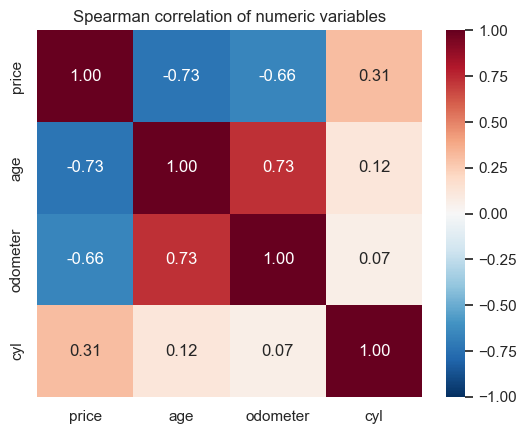

In [12]:
# Correlation of numeric variables (Spearman is robust to skew)
num_cols = ['price', 'age', 'odometer', 'cyl']
corr = df[num_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation of numeric variables')
plt.tight_layout()
plt.show()

In [13]:
# Inferential statistics: does each categorical variable explain differences in price?
# Kruskal-Wallis tests whether group medians differ; eta-squared (share of variance in log price
# explained by the group) tells us how MUCH, which matters because with 200,000+ rows every p-value is tiny.
rows = []
for col in cat_cols:
    groups = [g['log_price'].values for _, g in df.groupby(col) if len(g) >= 30]
    h, p = stats.kruskal(*groups)
    grand = df['log_price'].mean()
    ss_between = df.groupby(col)['log_price'].agg(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    ss_total = ((df['log_price'] - grand) ** 2).sum()
    rows.append({'feature': col, 'levels': df[col].nunique(), 'kruskal_p_value': p, 'eta_squared': ss_between / ss_total})
anova = pd.DataFrame(rows).sort_values('eta_squared', ascending=False).reset_index(drop=True)

# Same idea for the continuous variables: Spearman correlation with log price
for col in ['age', 'odometer']:
    rho, p = stats.spearmanr(df[col], df['log_price'])
    print(f'Spearman correlation of {col} with price: rho = {rho:.2f} (p = {p:.1e})')

anova.round({'eta_squared': 3})

Spearman correlation of age with price: rho = -0.73 (p = 0.0e+00)
Spearman correlation of odometer with price: rho = -0.66 (p = 0.0e+00)


,feature,levels,kruskal_p_value,eta_squared
0,type,14,0.0,0.126
1,manufacturer,41,0.0,0.111
2,transmission,4,0.0,0.108
3,fuel,6,0.0,0.087
4,condition,7,0.0,0.071
5,drive,4,0.0,0.070
6,paint_color,13,0.0,0.036
7,state,51,0.0,0.026
8,title_status,7,0.0,0.012


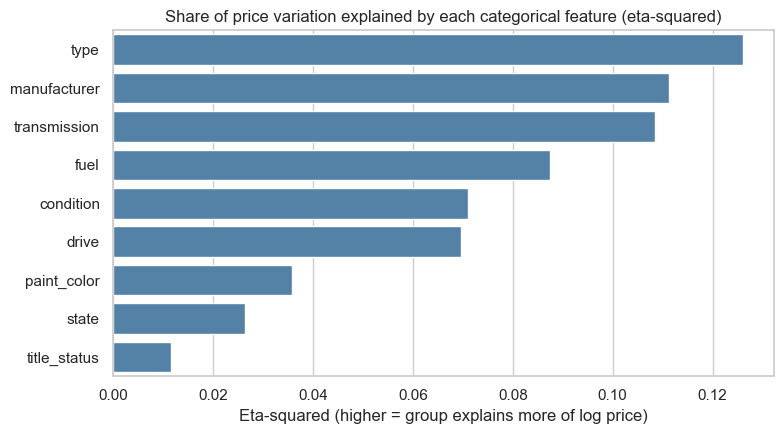

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=anova, x='eta_squared', y='feature', color='steelblue', ax=ax)
ax.set_title('Share of price variation explained by each categorical feature (eta-squared)')
ax.set_xlabel('Eta-squared (higher = group explains more of log price)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [15]:
# Confounding check: typical price, age and mileage within each condition / transmission group
for col in ['condition', 'transmission']:
    summary = df.groupby(col).agg(listings=('price', 'size'), median_price=('price', 'median'),
                                  median_age=('age', 'median'), median_odometer=('odometer', 'median'))
    print(summary.round(0).astype(int).to_string(), end='\n\n')

           listings  median_price  median_age  median_odometer
condition                                                     
excellent     61916         11500          10           107398
fair           4175          2900          18           177000
good          74142         17990           8            69786
like new      14458         14997           8            76058
new             549         17000           7            53000
salvage         333          2900          15           137874
unknown       85620         15955           8            94000

              listings  median_price  median_age  median_odometer
transmission                                                     
automatic       194712         12500          10           105031
manual           12329          9600          14           108546
other            33183         27990           4            26978
unknown            969         17995           8            87125



**Observations from the exploration**

* Price falls steadily with **age** and **mileage** (Spearman correlation with price of about -0.73 and -0.66). Age and odometer are themselves strongly related (older cars have more miles), so they have to be modelled together.
* **Condition is not a clean ladder in the raw data.** Salvage and fair cars are cheap (median about $2,900), but "good" cars have a *higher* median price than "excellent" ones. The reason is confounding: "excellent" listings are older (median 10 years, 107,000 miles) than "good" listings (8 years, 70,000 miles). Condition only shows its true effect once age and mileage are held constant, which is what the regression models do.
* **Vehicle type and manufacturer matter.** Pickups and trucks have the highest median prices, mini-vans and sedans the lowest. Among the most common brands, Ram, GMC, Lexus and Mercedes-Benz have the highest median prices; Honda, Nissan and Hyundai the lowest.
* **Every categorical variable passes the Kruskal-Wallis test with p ≈ 0**, but that is expected with 240,000 rows. The **eta-squared** values show which ones matter in practice: vehicle type (12.6% of the variation in log price), manufacturer (11.1%), transmission (10.8%), fuel (8.7%), condition (7.1%) and drive train (7.0%). Paint colour (3.6%), state (2.6%) and title status (1.2%) explain little. Part of the transmission, fuel and type effects is again confounding (e.g. listings with "other" transmission are much newer: median 4 years old vs. 10), so the models are needed to separate them.

### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

**Modelling plan**

* Target: `log_price`. Data split: 80% training / 20% held-out test (the test set is not touched until the final evaluation).
* Five regression models of increasing flexibility: a mean-only **baseline**, **Linear Regression**, **Ridge** and **Lasso** (regularised, interpretable) and two tree ensembles, **Random Forest** and **Histogram Gradient Boosting** (capture non-linear effects and interactions).
* Hyper-parameters are tuned with **grid search + cross-validation** (5-fold for the linear and boosting models, 3-fold for the random forest) on a 60,000-row sample of the training set for speed; final models are refit on the full training set.
* **Evaluation metric:** RMSE on log(price) (so errors are relative / percentage-like), plus MAE in dollars and R² for readability.

In [16]:
# Train / test split
features = ['age', 'odometer', 'cyl'] + cat_cols
X = df[features]
y = df['log_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Training rows: {len(X_train):,}   Test rows: {len(X_test):,}')

# Smaller tuning sample from the TRAINING data only (keeps grid search fast)
tune_idx = X_train.sample(60_000, random_state=RANDOM_STATE).index
X_tune, y_tune = X_train.loc[tune_idx], y_train.loc[tune_idx]
num_cols = ['age', 'odometer', 'cyl']
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training rows: 192,954   Test rows: 48,239


In [17]:
# Preprocessing for linear models: median-impute + scale numbers, one-hot encode categories.
# One level per category is dropped and acts as the reference ("baseline") level, so every coefficient
# reads as "this level vs. the baseline car". We choose common, easy-to-picture reference levels.
baseline_levels = {'manufacturer': 'ford', 'condition': 'good', 'fuel': 'gas', 'title_status': 'clean',
                   'transmission': 'automatic', 'drive': 'fwd', 'type': 'sedan', 'paint_color': 'white', 'state': 'ca'}
linear_prep = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop=[baseline_levels[c] for c in cat_cols], handle_unknown='ignore', min_frequency=50), cat_cols),
])

# Preprocessing for tree models: numbers pass through (NaN handled natively), categories ordinal-encoded
tree_prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
])
cat_positions = list(range(len(num_cols), len(num_cols) + len(cat_cols)))   # columns HistGradientBoosting treats as categorical

# Evaluation helper: metrics on the log scale and back in dollars
def evaluate(model, X_ev, y_ev):
    pred = model.predict(X_ev)
    return {
        'RMSE (log price)': mean_squared_error(y_ev, pred) ** 0.5,
        'MAE ($)': mean_absolute_error(np.expm1(y_ev), np.expm1(pred)),
        'R2': r2_score(y_ev, pred),
    }

results, best_models = [], {}

In [18]:
# Model 0: baseline (always predicts the average log price) - the bar every real model must clear
base = Pipeline([('prep', linear_prep), ('model', DummyRegressor(strategy='mean'))])
base_cv = -cross_val_score(base, X_tune, y_tune, cv=cv, scoring='neg_root_mean_squared_error').mean()
base.fit(X_train, y_train)
results.append({'Model': 'Baseline (mean)', 'Best parameters': '-', 'CV RMSE (log)': base_cv, **evaluate(base, X_test, y_test)})

# Model 1: ordinary least squares
ols = Pipeline([('prep', linear_prep), ('model', LinearRegression())])
ols_cv = -cross_val_score(ols, X_tune, y_tune, cv=cv, scoring='neg_root_mean_squared_error').mean()
ols.fit(X_train, y_train)
best_models['Linear Regression'] = ols
results.append({'Model': 'Linear Regression', 'Best parameters': '-', 'CV RMSE (log)': ols_cv, **evaluate(ols, X_test, y_test)})
pd.DataFrame(results).round(3)

,Model,Best parameters,CV RMSE (log),RMSE (log price),MAE ($),R2
0,Baseline (mean),-,0.845,0.846,10584.135,-0.000
1,Linear Regression,-,0.402,0.398,4404.585,0.779


In [19]:
# Model 2: Ridge regression - grid search over the regularisation strength
ridge_grid = GridSearchCV(
    Pipeline([('prep', linear_prep), ('model', Ridge())]),
    param_grid={'model__alpha': [0.1, 1, 10, 50, 100, 300]},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_grid.fit(X_tune, y_tune)
print('Best Ridge parameters:', ridge_grid.best_params_)

ridge = ridge_grid.best_estimator_.fit(X_train, y_train)      # refit on the full training set
best_models['Ridge'] = ridge
results.append({'Model': 'Ridge', 'Best parameters': str(ridge_grid.best_params_), 'CV RMSE (log)': -ridge_grid.best_score_, **evaluate(ridge, X_test, y_test)})

# Model 3: Lasso regression - can shrink weak features exactly to zero
lasso_grid = GridSearchCV(
    Pipeline([('prep', linear_prep), ('model', Lasso(max_iter=5000))]),
    param_grid={'model__alpha': [0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.003]},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_tune, y_tune)
print('Best Lasso parameters:', lasso_grid.best_params_)

lasso = lasso_grid.best_estimator_.fit(X_train, y_train)
best_models['Lasso'] = lasso
results.append({'Model': 'Lasso', 'Best parameters': str(lasso_grid.best_params_), 'CV RMSE (log)': -lasso_grid.best_score_, **evaluate(lasso, X_test, y_test)})
lasso_coefs = lasso.named_steps['model'].coef_
print(f'Lasso set {(lasso_coefs == 0).sum()} of {lasso_coefs.size} coefficients exactly to zero')
pd.DataFrame(results).round(3)

Best Ridge parameters: {'model__alpha': 1}


Best Lasso parameters: {'model__alpha': 3e-05}


Lasso set 6 of 138 coefficients exactly to zero


,Model,Best parameters,CV RMSE (log),RMSE (log price),MAE ($),R2
0,Baseline (mean),-,0.845,0.846,10584.135,-0.000
1,Linear Regression,-,0.402,0.398,4404.585,0.779
2,Ridge,{'model__alpha': 1},0.402,0.398,4404.082,0.779
3,Lasso,{'model__alpha': 3e-05},0.402,0.398,4401.888,0.779


In [20]:
# Model 4: Random Forest - grid search over depth and leaf size
rf_grid = GridSearchCV(
    Pipeline([('prep', tree_prep), ('model', RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid={'model__max_depth': [25, 40], 'model__min_samples_leaf': [1, 2, 4]},
    cv=3, scoring='neg_root_mean_squared_error')
rf_grid.fit(X_tune, y_tune)
print('Best Random Forest parameters:', rf_grid.best_params_)

rf = Pipeline([('prep', tree_prep), ('model', RandomForestRegressor(
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1,
    max_depth=rf_grid.best_params_['model__max_depth'],
    min_samples_leaf=rf_grid.best_params_['model__min_samples_leaf']))]).fit(X_train, y_train)
best_models['Random Forest'] = rf
results.append({'Model': 'Random Forest', 'Best parameters': str(rf_grid.best_params_), 'CV RMSE (log)': -rf_grid.best_score_, **evaluate(rf, X_test, y_test)})
pd.DataFrame(results).round(3)

Best Random Forest parameters: {'model__max_depth': 25, 'model__min_samples_leaf': 2}


,Model,Best parameters,CV RMSE (log),RMSE (log price),MAE ($),R2
0,Baseline (mean),-,0.845,0.846,10584.135,-0.000
1,Linear Regression,-,0.402,0.398,4404.585,0.779
2,Ridge,{'model__alpha': 1},0.402,0.398,4404.082,0.779
3,Lasso,{'model__alpha': 3e-05},0.402,0.398,4401.888,0.779
4,Random Forest,"{'model__max_depth': 25, 'model__min_samples_l...",0.384,0.344,2917.340,0.834


In [21]:
# Model 5: Histogram Gradient Boosting - grid search over learning rate, size and iterations
hgb_base = Pipeline([('prep', tree_prep), ('model', HistGradientBoostingRegressor(
    categorical_features=cat_positions, random_state=RANDOM_STATE))])
hgb_grid = GridSearchCV(
    hgb_base,
    param_grid={'model__learning_rate': [0.03, 0.05, 0.1],
                'model__max_leaf_nodes': [63, 127],
                'model__max_iter': [600, 1000]},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1)
hgb_grid.fit(X_tune, y_tune)
print('Best Gradient Boosting parameters:', hgb_grid.best_params_)

hgb = hgb_grid.best_estimator_.fit(X_train, y_train)
best_models['Gradient Boosting'] = hgb
results.append({'Model': 'Gradient Boosting', 'Best parameters': str(hgb_grid.best_params_), 'CV RMSE (log)': -hgb_grid.best_score_, **evaluate(hgb, X_test, y_test)})

Best Gradient Boosting parameters: {'model__learning_rate': 0.03, 'model__max_iter': 600, 'model__max_leaf_nodes': 127}


### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

In [22]:
# Model comparison: cross-validated error vs. error on the untouched test set
res = pd.DataFrame(results).set_index('Model').sort_values('RMSE (log price)')
res_show = res.copy()
res_show['MAE ($)'] = res_show['MAE ($)'].round(0).astype(int)
res_show[['CV RMSE (log)', 'RMSE (log price)', 'R2']] = res_show[['CV RMSE (log)', 'RMSE (log price)', 'R2']].round(3)
res_show

,Best parameters,CV RMSE (log),RMSE (log price),MAE ($),R2
Model,,,,,
Gradient Boosting,"{'model__learning_rate': 0.03, 'model__max_ite...",0.343,0.325,3179,0.852
Random Forest,"{'model__max_depth': 25, 'model__min_samples_l...",0.384,0.344,2917,0.834
Linear Regression,-,0.402,0.398,4405,0.779
Ridge,{'model__alpha': 1},0.402,0.398,4404,0.779
Lasso,{'model__alpha': 3e-05},0.402,0.398,4402,0.779
Baseline (mean),-,0.845,0.846,10584,-0.000


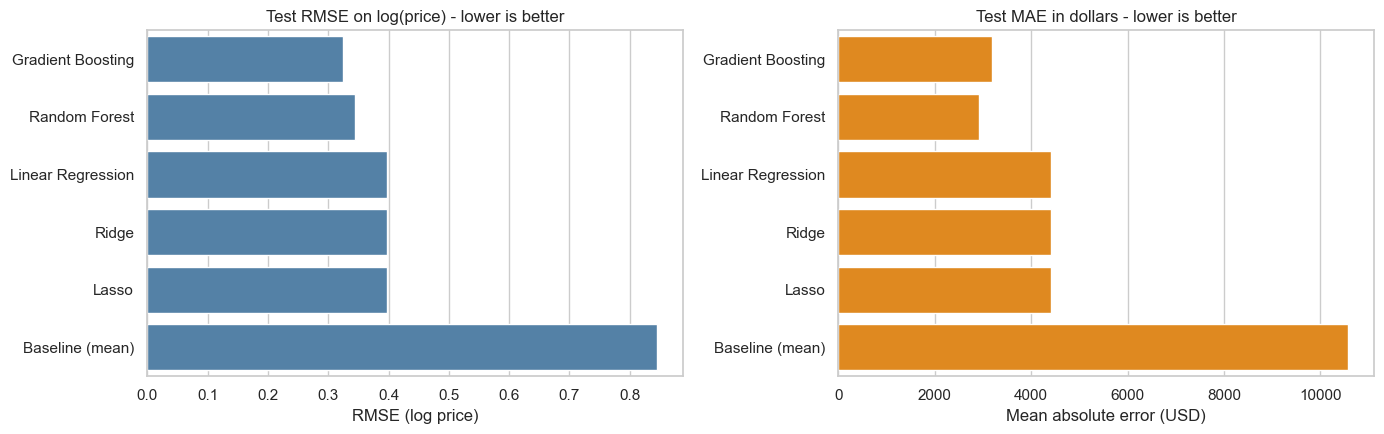

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = res.index
sns.barplot(x=res['RMSE (log price)'], y=order, color='steelblue', ax=axes[0])
axes[0].set_title('Test RMSE on log(price) - lower is better')
axes[0].set_xlabel('RMSE (log price)')
axes[0].set_ylabel('')
sns.barplot(x=res['MAE ($)'], y=order, color='darkorange', ax=axes[1])
axes[1].set_title('Test MAE in dollars - lower is better')
axes[1].set_xlabel('Mean absolute error (USD)')
axes[1].set_ylabel('')
plt.tight_layout()
plt.savefig('images/model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

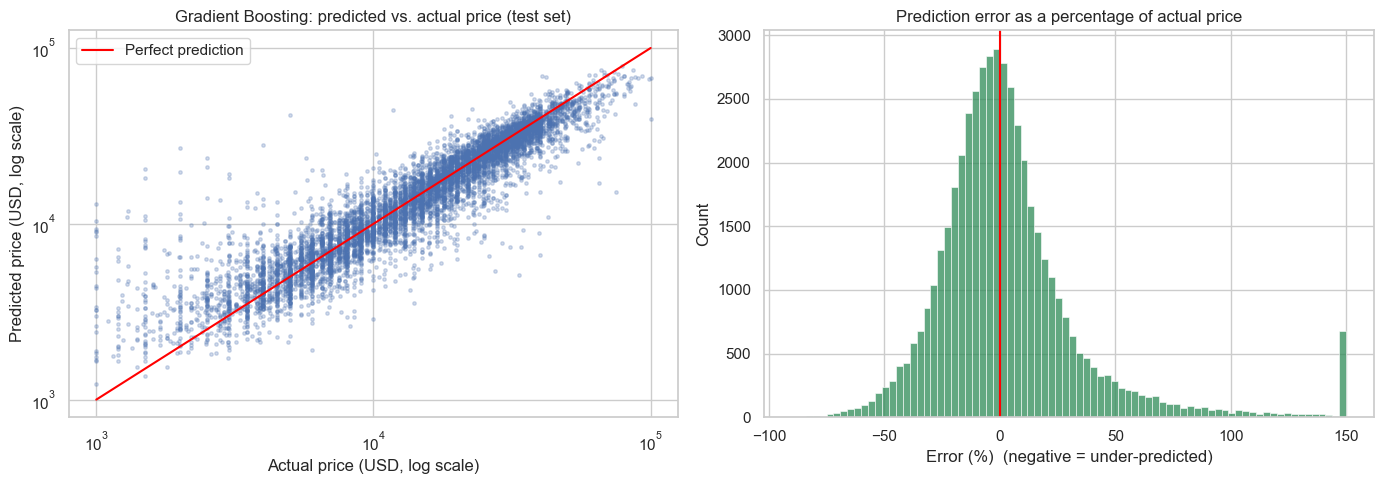

Median absolute % error: 14.5%
Share of test predictions within 25% of the actual price: 72%


In [24]:
# How well does the best model predict? Predicted vs. actual price on the test set
best_name = res.index[0]
best_model = best_models[best_name]
pred_price = np.expm1(best_model.predict(X_test))
actual_price = np.expm1(y_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
idx = np.random.RandomState(0).choice(len(actual_price), 8000, replace=False)
axes[0].scatter(actual_price.values[idx], pred_price[idx], s=6, alpha=0.25)
axes[0].plot([1_000, 100_000], [1_000, 100_000], color='red', lw=1.5, label='Perfect prediction')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_title(f'{best_name}: predicted vs. actual price (test set)')
axes[0].set_xlabel('Actual price (USD, log scale)')
axes[0].set_ylabel('Predicted price (USD, log scale)')
axes[0].legend()

pct_err = (pred_price - actual_price.values) / actual_price.values * 100
sns.histplot(pct_err.clip(-100, 150), bins=80, ax=axes[1], color='seagreen')
axes[1].axvline(0, color='red', lw=1.5)
axes[1].set_title('Prediction error as a percentage of actual price')
axes[1].set_xlabel('Error (%)  (negative = under-predicted)')
plt.tight_layout()
plt.savefig('images/predicted_vs_actual.png', dpi=100, bbox_inches='tight')
plt.show()

print(f'Median absolute % error: {np.median(np.abs(pct_err)):.1f}%')
print(f'Share of test predictions within 25% of the actual price: {(np.abs(pct_err) <= 25).mean() * 100:.0f}%')

### What drives price? Two complementary views

1. **Permutation importance (best model):** shuffle one feature at a time on the test set and measure how much the error grows. This works for any model, captures non-linear effects and is reported per original feature (all colour or manufacturer levels together).
2. **Ridge coefficients:** a linear model gives an interpretable size and direction for each attribute. Numeric features are converted to "per year" / "per 10,000 miles" effects, and every coefficient is converted to a percentage change in price because the target is log(price).

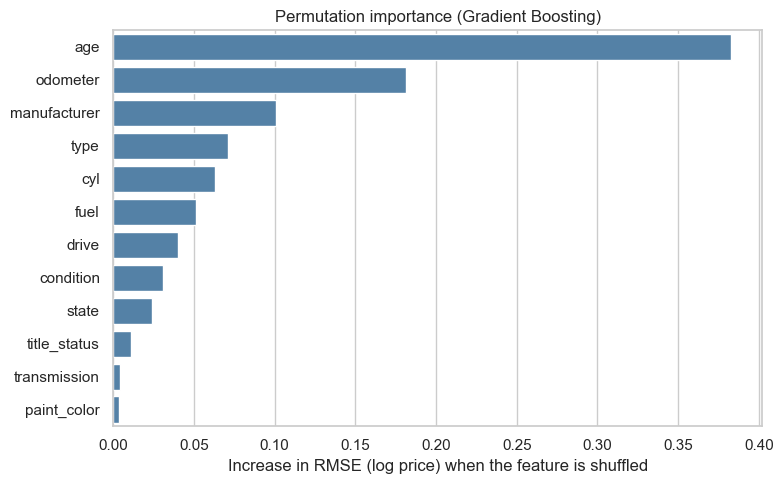

,feature,importance,std
0,age,0.383,0.002
1,odometer,0.181,0.002
2,manufacturer,0.101,0.001
3,type,0.071,0.001
4,cyl,0.063,0.001
5,fuel,0.052,0.001
6,drive,0.040,0.001
7,condition,0.031,0.001
8,state,0.024,0.000
9,title_status,0.011,0.000


In [25]:
# View 1: permutation importance on a 25,000-row test sample
test_sample = X_test.sample(25_000, random_state=RANDOM_STATE)
perm = permutation_importance(best_model, test_sample, y_test.loc[test_sample.index],
                              n_repeats=5, random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error', n_jobs=1)
imp = pd.DataFrame({'feature': test_sample.columns, 'importance': perm.importances_mean,
                    'std': perm.importances_std}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=imp, x='importance', y='feature', color='steelblue', ax=ax)
ax.set_title(f'Permutation importance ({best_name})')
ax.set_xlabel('Increase in RMSE (log price) when the feature is shuffled')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/permutation_importance.png', dpi=100, bbox_inches='tight')
plt.show()
imp.round(3).reset_index(drop=True)

Each additional year of age   :   -7.2% price
Each additional 10,000 miles  :   -3.8% price
Each additional cylinder      :   10.7% price


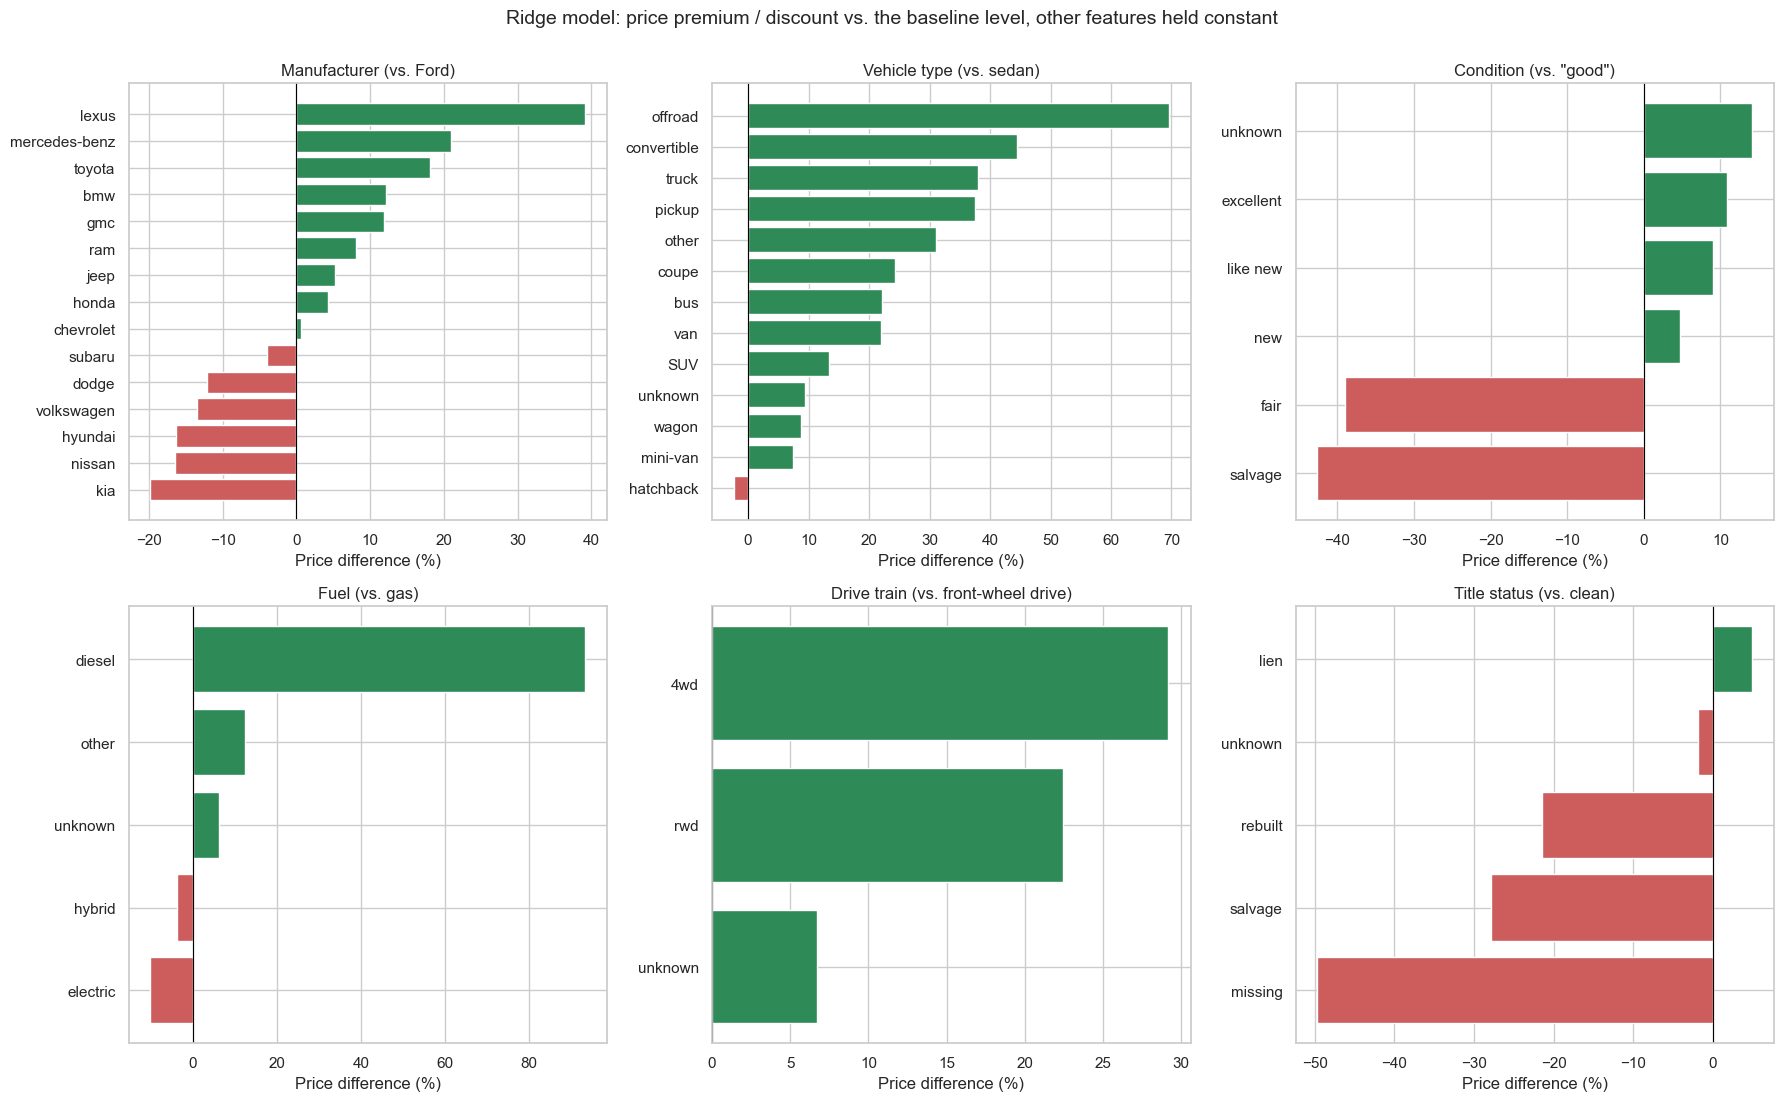

In [26]:
# View 2: Ridge coefficients translated into percentage price effects
names = ridge.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(ridge.named_steps['model'].coef_, index=names)
scaler = ridge.named_steps['prep'].named_transformers_['num'].named_steps['scale']

# Numeric features: convert the per-standard-deviation coefficient to a per-unit effect
per_unit = pd.Series(coefs[['num__age', 'num__odometer', 'num__cyl']].values / scaler.scale_, index=['age', 'odometer', 'cyl'])
print(f'Each additional year of age   : {(np.exp(per_unit["age"]) - 1) * 100:6.1f}% price')
print(f'Each additional 10,000 miles  : {(np.exp(per_unit["odometer"] * 10_000) - 1) * 100:6.1f}% price')
print(f'Each additional cylinder      : {(np.exp(per_unit["cyl"]) - 1) * 100:6.1f}% price')

# Categorical features: % price difference vs. the baseline level, all other features held constant
rows = []
for name, coef in coefs.filter(like='cat__').items():
    name = name.replace('cat__', '')
    if 'infrequent' in name:
        continue
    col = next(c for c in cat_cols if name.startswith(c + '_'))
    rows.append({'feature': col, 'level': name[len(col) + 1:], 'effect_pct': (np.exp(coef) - 1) * 100})
effects = pd.DataFrame(rows)

# Plot the most business-relevant features (one panel each, baseline level named in the title)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
panels = [('manufacturer', 'Manufacturer (vs. Ford)'), ('type', 'Vehicle type (vs. sedan)'), ('condition', 'Condition (vs. "good")'),
          ('fuel', 'Fuel (vs. gas)'), ('drive', 'Drive train (vs. front-wheel drive)'), ('title_status', 'Title status (vs. clean)')]
top_makes = X_train['manufacturer'].value_counts().head(16).index
for ax, (col, title) in zip(axes.ravel(), panels):
    sub = effects[effects['feature'] == col]
    if col == 'manufacturer':
        sub = sub[sub['level'].isin(top_makes)]
    sub = sub.sort_values('effect_pct')
    ax.barh(sub['level'], sub['effect_pct'], color=['indianred' if v < 0 else 'seagreen' for v in sub['effect_pct']])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(title)
    ax.set_xlabel('Price difference (%)')
plt.suptitle('Ridge model: price premium / discount vs. the baseline level, other features held constant', y=1.0, fontsize=14)
plt.tight_layout()
plt.savefig('images/price_effects_by_feature.png', dpi=100, bbox_inches='tight')
plt.show()

In [27]:
# The same effects as a table (percentage price difference vs. the baseline level)
table = (effects[effects['feature'].isin(['condition', 'fuel', 'drive', 'type', 'transmission', 'title_status'])]
         .set_index(['feature', 'level'])['effect_pct'].round(1).sort_index())
table.to_frame('% vs. baseline')

% vs. baseline
feature      level                      
condition    excellent              10.8
             fair                  -38.9
             like new                9.1
             new                     4.8
             salvage               -42.6
             unknown                14.2
drive        4wd                    29.1
             rwd                    22.4
             unknown                 6.7
fuel         diesel                 93.4
             electric              -10.1
             hybrid                 -3.6
             other                  12.4
             unknown                 6.3
title_status lien                    5.0
             missing               -49.7
             rebuilt               -21.5
             salvage               -27.8
             unknown                -1.8
transmission manual                 15.4
             other                  13.2
             unknown                 9.1
type         SUV                    13.4
             bus                    22.2
             convertible            44.5
             coupe                  24.4
             hatchback              -2.4
             mini-van                7.4
             offroad                69.5
             other                  31.0
             pickup                 37.5
             truck                  38.0
             unknown                 9.4
             van                    21.9
             wagon                   8.7

In [28]:
# Manufacturer effects for the 16 most common brands (% price difference vs. Ford)
make_effects = effects[(effects['feature'] == 'manufacturer') & effects['level'].isin(top_makes)]
make_effects.set_index('level')['effect_pct'].round(1).sort_values().to_frame('% vs. Ford').T

level,kia,nissan,hyundai,volkswagen,dodge,subaru,chevrolet,honda,jeep,ram,gmc,bmw,toyota,mercedes-benz,lexus
% vs. Ford,-19.8,-16.5,-16.3,-13.5,-12.1,-4.1,0.6,4.3,5.2,8.0,11.9,12.1,18.1,21.0,39.2


In [29]:
# Does the dollar-error depend on price level? (honest check of where the model is weaker)
band = pd.cut(actual_price, [0, 5_000, 10_000, 20_000, 35_000, 100_000],
              labels=['< $5k', '$5k-10k', '$10k-20k', '$20k-35k', '> $35k'])
perf = pd.DataFrame({'band': band.values, 'abs_pct_err': np.abs(pct_err), 'abs_err_usd': np.abs(pred_price - actual_price.values)})
perf.groupby('band', observed=True).agg(listings=('abs_pct_err', 'size'),
                                        median_abs_pct_error=('abs_pct_err', 'median'),
                                        mean_abs_error_usd=('abs_err_usd', 'mean')).round(1)

,listings,median_abs_pct_error,mean_abs_error_usd
band,,,
< $5k,6992,26.1,1644.5
$5k-10k,10883,15.9,1589.6
$10k-20k,13383,14.3,2753.9
$20k-35k,11349,11.0,3909.2
> $35k,5631,12.3,7682.5


### Evaluation: what did we learn?

**Evaluation metric and why.** The main metric is **RMSE on log(price)**. Prices span $1,000 to $100,000, so a plain-dollar RMSE would be dominated by expensive cars. On the log scale an error means "off by a percentage", which is how dealers think about pricing. We also report **MAE in dollars** (the average miss in plain money) and **R²** (share of price variation the model explains).

**Model comparison (held-out test set, 48,239 listings)**

| Model | RMSE (log price) | MAE ($) | R² |
|---|---|---|---|
| Baseline (always the average) | 0.846 | 10,584 | 0.00 |
| Linear / Ridge / Lasso | 0.398 | about 4,400 | 0.78 |
| Random Forest | 0.344 | 2,917 | 0.83 |
| **Gradient Boosting (selected)** | **0.325** | 3,179 | **0.85** |

* All models beat the baseline by a wide margin, so the vehicle attributes contain real pricing signal.
* **Ridge and Lasso are no better than plain linear regression.** With 190,000+ training rows and only a dozen features there is little over-fitting to shrink; the best regularisation strengths were tiny and Lasso set only 6 of the 138 coefficients to zero.
* **The tree ensembles are clearly better than the linear models** (R² 0.83-0.85 vs. 0.78), which tells us that price depends on non-linear effects and interactions, e.g. depreciation is steep in the first few years and flattens later, and the value of 4WD or diesel differs by vehicle type.
* Gradient Boosting has the lowest log-scale error and the best R². Random Forest has a slightly lower average *dollar* error ($2,917 vs. $3,179) because Gradient Boosting was selected on log-scale RMSE, which weights errors on cheaper cars more heavily. Either is a sensible choice; we choose Gradient Boosting because the metric was fixed in advance.
* Cross-validation RMSE for the tree models (0.343-0.384) is higher than their test RMSE (0.325-0.344) because the grid search ran on a 60,000-row sample; the final models are trained on 192,954 rows and benefit from more data. For the linear models, CV and test errors agree (0.402 vs. 0.398), which indicates no sign of over-fitting.

**How good is "good"?** For the selected model the *median* prediction is off by **14.5%**, and **72% of predictions are within 25%** of the actual asking price. The model is least accurate for cheap cars (median error about 26% below $5,000, where condition problems and idiosyncratic listings dominate) and most accurate between $20,000 and $35,000 (about 11%).

**What drives price?** Both interpretation methods agree.

* **Permutation importance:** age (0.38) is the most important feature, followed by odometer (0.18), manufacturer (0.10), vehicle type (0.07), number of cylinders (0.06), fuel type (0.05), drive train (0.04) and condition (0.03). Paint colour and transmission are almost irrelevant once the other features are known.
* **Ridge coefficients** (holding everything else constant): each additional year of age is associated with about **7% lower price**, each additional 10,000 miles with about **4% lower price**, and each extra cylinder with about **11% higher price** (engine size also stands in for vehicle class). Against a baseline car (Ford, sedan, gas, automatic, front-wheel drive, clean title, "good" condition): diesel +93%, 4WD +29%, rear-wheel drive +22%, pickups and trucks about +38%, convertibles +45%; Lexus +39%, Mercedes-Benz +21%, Toyota +18% versus Ford, while Kia, Nissan and Hyundai are 16-20% lower; rebuilt titles -22%, salvage titles -28%, "fair" condition -39% and "salvage" condition -43%.

**Caveats we keep in mind**

* The data are **asking prices from online listings, not final sale prices**, and the coefficients show **association, not cause** (painting a car a different colour will not change its price by the amount shown for another colour, and buying diesel cars will not automatically raise margins).
* Listings with an unusual field value are not random: e.g. a title status explicitly marked "missing" is associated with a 50% lower price, and a blank ("unknown") condition with a 14% *higher* price than "good", most likely because of who posts such listings (private sellers vs. dealers). These effects describe the listing, not only the car.
* "New" condition appears in only 549 cleaned listings, so its estimate is unreliable.
* Linear coefficients assume a constant percentage effect per year or per 10,000 miles; the boosting model shows the true relationship is curved.
* We removed prices outside $1,000-$100,000, very old and high-mileage vehicles, and 30% of rows were duplicates. The conclusions apply to everyday used cars in that range.

**Do earlier phases need revisiting?** The results meet the business goal (a clear, stable ranking of price drivers and a model that predicts within about 15% for a typical car), so no re-work of the business question is needed. Two improvements would raise accuracy further: using the vehicle **`model`** (about 30,000 free-text spellings that need cleaning) and a finer **trim / options** description.

### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

## Report for Used Car Dealers: What Drives the Price of a Used Car?

*Based on 241,193 cleaned used-car listings ($1,000-$100,000, model years 1995-2022). Our best prediction model explains about 85% of the differences in asking prices, and 72% of its predictions land within 25% of the real asking price.*

### Key findings

1. **Age and mileage matter most, by a wide margin.** Every extra year of age is associated with roughly **7% lower price**, and every extra 10,000 miles with roughly **4% lower price**. Age is about twice as influential as mileage.
2. **What the car is matters next:** brand and body type. Compared with a typical Ford sedan, **pickups and trucks sell for about 38% more**, 4-wheel-drive for about 29% more and **diesel for about 93% more** (with age, mileage and brand held equal). Lexus (+39%), Mercedes-Benz (+21%) and Toyota (+18%) carry a price premium over Ford, while Kia, Nissan and Hyundai sell 16-20% lower.
3. **Paperwork and condition carry real penalties.** **Salvage and rebuilt titles sell 28% and 22% lower**, and cars in "fair" or "salvage" condition 39-43% lower. Cars in "excellent" or "like new" condition earn only about **9-11% more** than "good".
4. **Cosmetics hardly matter.** Paint colour and transmission type add almost nothing once age, mileage and type are known.
5. **Fuel type is not a free premium for greener cars.** Hybrids are priced about the same as gas cars and electric cars about 10% lower, at the same age and mileage.

### Recommendations for your inventory

| Action | Why |
|---|---|
| **Buy newer, lower-mileage cars when the acquisition price allows.** Use "-7% per year, -4% per 10,000 miles" as a rule of thumb when judging an auction or trade-in price. | These two factors are by far the most important drivers of price in the model. |
| **Stock more pickups, trucks, 4WD and diesel vehicles, and well-regarded brands (Toyota, Lexus).** | Buyers pay clearly more for them. *Check your purchase costs first: a premium only helps if you did not already pay it when buying the car.* |
| **Avoid or heavily discount salvage / rebuilt titles and cars in fair condition.** | Buyers discount them by 20-45%. |
| **Always list the title status, condition, drive train and fuel type in every ad.** | Listings whose title status is marked "missing" sell for about half the price of comparable clean-title cars; complete, documented listings avoid that discount. |
| **Do not pay extra for paint colour or transmission type when buying.** | They have almost no influence on price. |
| **Use the model as a price sanity check, not as the final price.** | Typical error is about 14%; it is less reliable below $5,000 (about 26%) and for rare vehicles. |

### Limits to keep in mind

* The data are online **asking prices**, not what buyers finally paid, and the percentages describe **associations**, not guaranteed results.
* Results apply to everyday used cars between $1,000 and $100,000.

### Next steps

1. **Validate with your own sales data:** compare predicted prices with what your dealership actually sold cars for, and recalibrate.
2. **Add richer information:** the exact **model and trim level** (about 30,000 free-text spellings that need cleaning), listing date, photos and description text should raise accuracy further.
3. **Track seasonality and regional differences** (e.g. convertibles and 4WD demand by state and month).
4. **Turn the model into a simple pricing tool** (enter a car's details, get an expected price range) and monitor its accuracy over time.